(4, 912, 912)
solved 10 frequencies: [0.8 1.6 2.4 3.2 4.  4.8 5.6 6.4 7.2 8. ] kHz


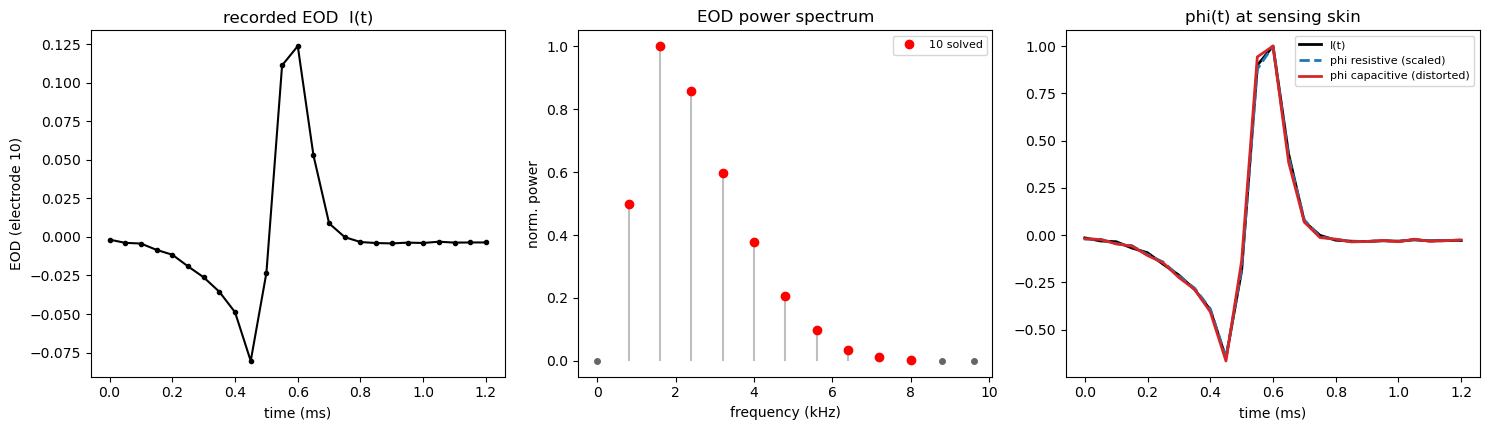

In [5]:
import numpy as np, pandas as pd, re
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.ndimage import zoom
import matplotlib.pyplot as plt

mask_example_3_frames = np.load('data/mask_example_3_frames.npy')

fish_mask = mask_example_3_frames[0] # frame 0
print(fish_mask.shape)

def fish_axis_from_mask(mask, tank_shape=None):
    """Mask (P,P) bool -> (tail, head) endpoints in [0,1] tank coords.
       Long axis from PCA; tail = the narrower end (electric organ side)."""
    ys, xs = np.nonzero(mask)
    pts = np.column_stack([xs, ys]).astype(float)      # (n, 2) as (x, y)
    c = pts.mean(0)
    v = np.linalg.svd(pts - c, full_matrices=False)[2][0]   # principal direction (unit)

    t = (pts - c) @ v                                  # coordinate along the axis
    p_lo, p_hi = c + t.min()*v, c + t.max()*v          # the two extreme tips

    # --- which tip is the tail? the tail end is thinner ---
    w = (pts - c) @ np.array([-v[1], v[0]])            # perpendicular coordinate (width)
    L = t.max() - t.min()
    near_lo = np.abs(t - t.min()) < 0.25*L             # pixels in the first quarter
    near_hi = np.abs(t - t.max()) < 0.25*L             # pixels in the last quarter
    width_lo = w[near_lo].std() if near_lo.any() else np.inf
    width_hi = w[near_hi].std() if near_hi.any() else np.inf
    tail_px, head_px = (p_lo, p_hi) if width_lo < width_hi else (p_hi, p_lo)

    H, W = mask.shape
    to_tank = lambda p: np.array([p[0]/(W-1), p[1]/(H-1)])   # pixels -> [0,1]
    return to_tank(tail_px), to_tank(head_px)

# ============================================================
# 0.  GRID BOOKKEEPING
# ============================================================
def idx(i, j, N): return i * N + j
def to_grid(v, N): return np.asarray(v).reshape(N, N)

# ============================================================
# 1.  GEOMETRY:  masks -> occupancy level-set -> theta matrices
# ============================================================
def occupancy_field(masks, N, skip=None):
    """(n_fish,P,P) bool (or dict) -> smooth NxN occupancy in [0,1]; occ>0.5 = fish."""
    if isinstance(masks, dict):
        masks = [masks[k] for k in sorted(masks)]
    occ = np.zeros((N, N))
    for f, m in enumerate(masks):
        if (skip is not None and f == skip) or not np.any(m):
            continue
        P = m.shape[0]
        occ = np.maximum(occ, zoom(m.astype(float), N / P, order=1)[:N, :N])  # order=1 => sub-cell edge
    return occ

def theta_matrices(occ, level=0.5):
    """Boundary-crossing fraction on every edge (theta_x along +x, theta_y along +y)."""
    def cross(a, b):
        cut = (a - level) * (b - level) < 0
        d = a - b
        th = np.divide(a - level, d, out=np.full_like(a, 0.5), where=np.abs(d) > 1e-12)
        return np.where(cut, np.clip(th, 1e-6, 1 - 1e-6), 0.5)
    return cross(occ[:-1, :], occ[1:, :]), cross(occ[:, :-1], occ[:, 1:])

# ============================================================
# 2.  MATERIALS:  occupancy + omega -> complex admittivity gamma
# ============================================================
def material_fields(occ, omega, sigma_water=1.0, eps_water=0.0,
                                 sigma_fish=5.0,  eps_fish=0.0):
    inside = occ > 0.5
    sigma = np.where(inside, sigma_fish, sigma_water)
    eps   = np.where(inside, eps_fish,   eps_water)
    return sigma + 1j * omega * eps                          # gamma = sigma + i*omega*eps

# ============================================================
# 3.  MATRIX:  gamma + thetas -> A   (theta-weighted complex harmonic mean)
# ============================================================
def build_A(gamma, tx, ty, N):
    rows, cols, vals = [], [], []
    def edge(k, kk, gC, gM, th):
        w = gC if gC == gM else 1.0 / (th / gC + (1.0 - th) / gM)
        rows.append(k); cols.append(kk); vals.append(w); return w
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N); ws = 0j
            if i > 0:    ws += edge(k, idx(i-1, j, N), gamma[i, j], gamma[i-1, j], 1 - tx[i-1, j])
            if i < N-1:  ws += edge(k, idx(i+1, j, N), gamma[i, j], gamma[i+1, j],     tx[i,   j])
            if j > 0:    ws += edge(k, idx(i, j-1, N), gamma[i, j], gamma[i, j-1], 1 - ty[i, j-1])
            if j < N-1:  ws += edge(k, idx(i, j+1, N), gamma[i, j], gamma[i, j+1],     ty[i,   j])
            rows.append(k); cols.append(k); vals.append(-ws)
    return sp.coo_matrix((vals, (rows, cols)), shape=(N*N, N*N), dtype=complex).tocsr()

def solve_potential(A, b, pin=0):
    """Solve A phi = b (complex, singular Neumann). Complex-symmetric -> LU, not CG."""
    M = (-A).tolil(); rhs = -(np.asarray(b).ravel().astype(complex))
    M[pin, :] = 0; M[pin, pin] = 1; rhs[pin] = 0
    return splu(M.tocsc()).solve(rhs) - 0  # (mean removed by caller if wanted)

# ============================================================
# 4.  SOURCE:  multipole (tail sink -1, body sources +1/n), deposited to b
# ============================================================
def place_current_on_grid(b, x, y, I, h, N):
    fi, fj = x/h, y/h; i, j = int(fi), int(fj); a, c = fi - i, fj - j
    for di, wx in ((0, 1-a), (1, a)):
        for dj, wy in ((0, 1-c), (1, c)):
            ii, jj = i+di, j+dj
            if 0 <= ii < N and 0 <= jj < N: b[ii, jj] += I*wx*wy

def multipole_sources(tail, head, n, I0=1.0):
    tail, head = np.asarray(tail, float), np.asarray(head, float)
    i = np.arange(n+1)
    pos = tail + np.outer(i/n, head - tail)
    m = np.full(n+1, 1.0/n); m[0] = -1.0
    return pos, m*I0

def build_multipole_b(pos, cur, h, N):
    b = np.zeros((N, N))
    for (x, y), Ii in zip(pos, cur):
        place_current_on_grid(b, x, y, Ii, h, N)
    return b - b.mean()

# ============================================================
# 5.  EOD SPECTRUM:  pick the frequencies that carry the power
# ============================================================
def eod_frequencies(I_rec, dt, power_keep=0.999, detrend=True):
    x = np.asarray(I_rec, float);  x = x - x.mean() if detrend else x
    n = len(x); Ihat = np.fft.rfft(x); f = np.fft.rfftfreq(n, dt); Pw = np.abs(Ihat)**2
    order = np.argsort(Pw)[::-1]; frac = np.cumsum(Pw[order]) / Pw.sum()
    nk = int(np.searchsorted(frac, power_keep) + 1)
    keep = np.sort(order[:nk]); keep = keep[f[keep] > 0]
    return keep, 2*np.pi*f, Ihat, n, f, Pw

# ============================================================
# 6.  TIME-DOMAIN FIELD:  solve only the kept frequencies, iFFT
# ============================================================
def solve_eod_field(I_rec, dt, occ, tx, ty, N, b_unit, probes,
                    sigma_water=1.0, eps_water=0.0, sigma_fish=5.0, eps_fish=0.0,
                    power_keep=0.999):
    keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt, power_keep)
    pidx = [idx(i, j, N) for i, j in probes]
    phi_hat = np.zeros((len(Ihat), len(probes)), complex)
    for k in keep:
        A = build_A(material_fields(occ, om[k], sigma_water, eps_water, sigma_fish, eps_fish), tx, ty, N)
        psi = solve_potential(A, b_unit)
        phi_hat[k] = Ihat[k] * psi[pidx]
    phi_t = np.fft.irfft(phi_hat, n=n_t, axis=0)                 # (n_t, n_probes)
    return phi_t, keep, freqs, Pw

# ============================================================
# 7.  READ ONE EOD FROM THE CSV -> waveform + endpoints
# ============================================================
def load_eod_row(csv, row=0, fs=20000.0):
    df = pd.read_csv(csv)
    pat = re.compile(r"electrode_(\d+)_time_(\d+)")
    cells = [(int(m.group(1)), int(m.group(2)), c) for c in df.columns for m in [pat.match(c)] if m]
    ne = max(e for e,_,_ in cells); nt = max(t for _,t,_ in cells)
    E = np.full((ne, nt), np.nan)
    for e, t, c in cells: E[e-1, t-1] = df.iloc[row][c]
    best = int(np.argmax(E.std(axis=1)))                         # most active electrode
    return E, best, 1.0/fs

# ============================================================
#                       DRIVER
# ============================================================
N = 120; h = 1.0/(N-1)

# --- your data ---
# fish_mask : (4, P, P) bool stack for this frame
# fish 0 = the emitter (skipped from sigma, present as multipole source)
occ = occupancy_field(fish_mask, N, skip=0)
tx, ty = theta_matrices(occ)

# source geometry from fish 0's mask (tail, head endpoints in [0,1])
tail, head = fish_axis_from_mask(fish_mask[0])                             # your endpoint function
pos, cur   = multipole_sources(tail, head, n=8, I0=1.0)
b_unit     = build_multipole_b(pos, cur, h, N)

# EOD waveform from the recording
E, best, dt = load_eod_row("first_100_eods.csv", row=0, fs=20000.0)
I_rec = E[best]

# probe cells = the skin of the SENSING fish (here: fish 1's outline cells)
sensing = (occupancy_field(fish_mask[1:2], N) > 0.5)
probes  = list(zip(*np.nonzero(sensing)))[::5]                   # subsample its cells

# solve: resistive and capacitive
phi_res, keep, freqs, Pw = solve_eod_field(I_rec, dt, occ, tx, ty, N, b_unit, probes,
                                            sigma_fish=5.0, eps_fish=0.0)
phi_cap, _, _, _         = solve_eod_field(I_rec, dt, occ, tx, ty, N, b_unit, probes,
                                            sigma_fish=5.0, eps_fish=2e-4)
t = np.arange(len(I_rec))*dt
print(f"solved {len(keep)} frequencies: {np.round(freqs[keep]/1e3,2)} kHz")

# ============================================================
#                       PLOTS
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))

# (a) chosen EOD + power spectrum markers
ax[0].plot(t*1e3, I_rec - I_rec.mean(), 'ko-', ms=3)
ax[0].set_xlabel("time (ms)"); ax[0].set_ylabel("EOD (electrode %d)" % (best+1))
ax[0].set_title("recorded EOD  I(t)")

ax[1].vlines(freqs/1e3, 0, Pw/Pw.max(), color='0.75')
ax[1].plot(freqs/1e3, Pw/Pw.max(), 'o', color='0.4', ms=4)
ax[1].plot(freqs[keep]/1e3, (Pw/Pw.max())[keep], 'ro', label=f"{len(keep)} solved")
ax[1].set_xlabel("frequency (kHz)"); ax[1].set_ylabel("norm. power")
ax[1].set_title("EOD power spectrum"); ax[1].legend(fontsize=8)

# (c) phi(t) on the sensing skin: resistive (scaled) vs capacitive (distorted)
nr = lambda x: x/np.max(np.abs(x))
ax[2].plot(t*1e3, nr(I_rec - I_rec.mean()), 'k', lw=2, label="I(t)")
ax[2].plot(t*1e3, nr(phi_res[:, 0]), '--', color="#1f77b4", lw=2, label="phi resistive (scaled)")
ax[2].plot(t*1e3, nr(phi_cap[:, 0]),        color="#d62728", lw=2, label="phi capacitive (distorted)")
ax[2].set_xlabel("time (ms)"); ax[2].set_title("phi(t) at sensing skin"); ax[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig("eod_pipeline.png", dpi=300)   # or plt.show() in a notebook

In [7]:
from scipy.ndimage import binary_erosion

EPS0 = 8.854187817e-12

sigma_water = 0.023

sigma_skin = 0.002
sigma_body = 0.55

eps_water = 80 * EPS0
eps_skin = 8000 * EPS0
eps_body = 600 * EPS0

def build_skin_body(mask):
    """
    One-pixel thick skin.
    """

    interior = binary_erosion(mask)
    skin = mask & (~interior)

    return skin, interior

def material_fields_heterogeneous(
        fish_masks,
        omega,
        N,
        sigma_water=0.023,
        sigma_skin=0.002,
        sigma_body=0.55,
        eps_water=80*EPS0,
        eps_skin=8000*EPS0,
        eps_body=600*EPS0):

    sigma = sigma_water*np.ones((N,N))
    eps = eps_water*np.ones((N,N))

    for mask in fish_masks:

        maskN = zoom(mask.astype(float), N/mask.shape[0], order=0)[:N,:N] > 0.5

        skin, body = build_skin_body(maskN)

        sigma[skin] = sigma_skin
        sigma[body] = sigma_body

        eps[skin] = eps_skin
        eps[body] = eps_body

    gamma = sigma + 1j*omega*eps

    return gamma